<a href="https://colab.research.google.com/github/mohithkumarreddyputtur-sketch/DEEP-LEARINING-/blob/main/Experiment_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Epoch 1/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 75ms/step - accuracy: 0.3689 - loss: 1.7385 - val_accuracy: 0.4500 - val_loss: 1.5292
Epoch 2/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 23s 85ms/step - accuracy: 0.4944 - loss: 1.4092 - val_accuracy: 0.5045 - val_loss: 1.4082
Epoch 3/3
250/250 ━━━━━━━━━━━━━━━━━━━━ 19s 74ms/step - accuracy: 0.5485 - loss: 1.2661 - val_accuracy: 0.5475 - val_loss: 1.2566
Test: [1.2537791728973389, 0.5552499890327454]
[[40  3  3  0  1  0  3  0  2  5]
 [ 2 34  0  1  0  0  1  1  2  0]
 [ 4  2 19  3  7  5 10  1  0  0]
 [ 2  1  4  5  4 17 10  4  0  2]
 [ 4  1  3  3  9  4 10  6  0  0]
 [ 1  0  3  4  2 27  3  8  0  0]
 [ 0  2  3  1  5  0 42  0  1  0]
 [ 1  2  0  4  1  7  0 30  2  0]
 [17 11  2  2  0  0  1  2 20  2]
 [ 1 15  0  0  0  1  2  2  2 33]]


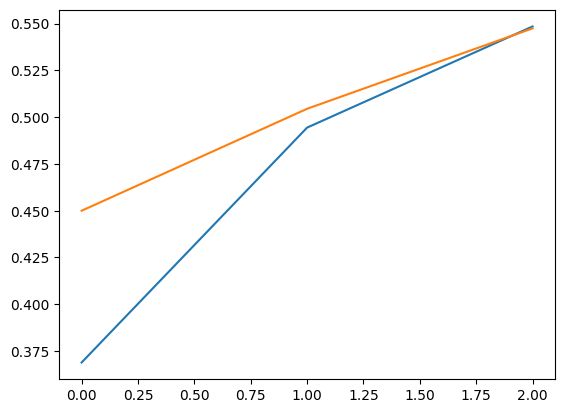

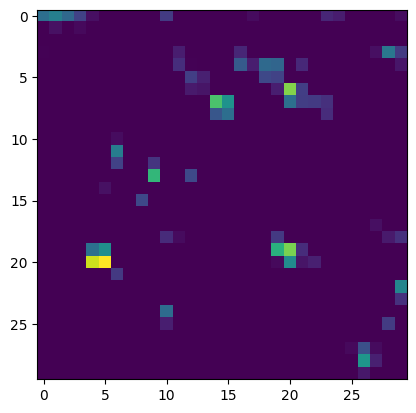

In [2]:
import tensorflow as tf, matplotlib.pyplot as plt, numpy as np
from sklearn.metrics import confusion_matrix
(x,y),(xt,yt)=tf.keras.datasets.cifar10.load_data(); x=x[:20000]; y=y[:20000]; xt=xt[:4000]; yt=yt[:4000]
x=x.astype('float32')/255; xt=xt.astype('float32')/255; y=y.ravel(); yt=yt.ravel()
m=tf.keras.Sequential([tf.keras.layers.Input((32,32,3)),tf.keras.layers.Conv2D(32,3,activation='relu'),tf.keras.layers.MaxPooling2D(),tf.keras.layers.Conv2D(64,3,activation='relu'),tf.keras.layers.MaxPooling2D(),tf.keras.layers.Flatten(),tf.keras.layers.Dense(128,activation='relu'),tf.keras.layers.Dense(10,activation='softmax')])
m.compile('adam','sparse_categorical_crossentropy',metrics=['accuracy']); h=m.fit(x,y,validation_split=.2,epochs=3,batch_size=64,verbose=1)
print('Test:',m.evaluate(xt,yt,verbose=0)); p=m.predict(xt[:500],verbose=0).argmax(1); print(confusion_matrix(yt[:500],p))
plt.plot(h.history['accuracy']); plt.plot(h.history['val_accuracy']); plt.show()
# Build the sequential model by calling or building it to define the inputs, or access the first layer's input directly
fm=tf.keras.Model(m.layers[0].input, m.layers[0].output); plt.imshow(fm.predict(x[:1],verbose=0)[0,:,:,0]); plt.show()